<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/sessions/Session02_preprocessing_and_pipelines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۲: پیش‌پردازش داده و Pipeline

در ترم علم داده یاد گرفتیم داده را پاک کنیم و با EDA بشناسیم. در این جلسه یاد می‌گیریم داده را **برای مدل** آماده کنیم؛ طوری که هیچ اطلاعاتی از دادهٔ آزمون به مدل نشت نکند.

### اهداف این جلسه

- مرور سریع EDA با نگاه یادگیری ماشین: کدام ویژگی‌ها به هدف ربط دارند؟
- شناخت و رفع مقادیر گمشده
- تبدیل ویژگی‌های دسته‌ای به عدد با روش درست (One-Hot و Ordinal)
- مقیاس‌بندی ویژگی‌ها و اینکه چه زمانی لازم است
- مهندسی ویژگی ساده
- آشنایی با **نشت داده (Data Leakage)**، یکی از خطرناک‌ترین اشتباه‌ها در یادگیری ماشین
- ساختن یک **Pipeline** کامل با `ColumnTransformer`

در عمل، بیشتر وقت یک پروژهٔ یادگیری ماشین صرف شناخت و آماده‌سازی داده می‌شود، نه انتخاب مدل. مدل خوب روی دادهٔ بد، نتیجهٔ بد می‌دهد.

## ۱. مجموعه‌داده: مسافران کشتی تایتانیک

این مجموعه‌داده اطلاعات ۸۹۱ مسافر کشتی تایتانیک را دارد. **مسئله:** پیش‌بینی اینکه یک مسافر از حادثه جان سالم به در برده است یا نه (`survived`). این یک مسئلهٔ طبقه‌بندی دودویی است.

همهٔ داده‌های این دوره از پوشهٔ `data` همین مخزن در GitHub خوانده می‌شوند؛ بنابراین نوت‌بوک‌ها در Colab بدون آپلود فایل اجرا می‌شوند.

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"

df = pd.read_csv(DATA_URL + "titanic.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. نگاه کلی به داده

EDA را در ترم علم داده مفصل دیدیم؛ اینجا فقط مرور سریعی می‌کنیم تا بدانیم برای مدل‌سازی با چه چیزی روبه‌رو هستیم. سه سؤال اول: چند سطر و ستون داریم؟ نوع هر ستون چیست؟ کجا مقدار گمشده داریم؟

</div>

In [2]:
print("Shape:", df.shape)
df.info()

Shape: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [3]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(1)
pd.DataFrame({"missing": missing, "percent": missing_pct}).query("missing > 0")

,missing,percent
age,177,19.9
embarked,2,0.2
deck,688,77.2
embark_town,2,0.2


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

- ستون `deck` بیش از ۷۷٪ مقدار گمشده دارد؛ پر کردن آن عملاً حدس زدن است، پس حذفش می‌کنیم.
- ستون `age` حدود ۲۰٪ گمشده دارد؛ مهم است و باید پر شود.
- ستون `embarked` فقط ۲ مقدار گمشده دارد.

### ستون‌های تکراری و نشت هدف

قبل از هر کاری باید معنای هر ستون را بدانیم. در این داده چند ستون اطلاعات تکراری دارند:

- `class` همان `pclass` است، به شکل متن
- `embark_town` همان `embarked` است، با نام کامل شهر
- `who` و `adult_male` از روی `sex` و `age` ساخته شده‌اند

و یک ستون بسیار خطرناک: **`alive`** که همان `survived` است، با مقدار «yes/no». اگر این ستون را به‌عنوان ویژگی به مدل بدهیم، مدل دقت ۱۰۰٪ می‌گیرد، ولی کاملاً بی‌فایده است؛ چون در دنیای واقعی، هنگام پیش‌بینی، این اطلاعات را نداریم. به این اشتباه **نشت هدف (Target Leakage)** می‌گویند.

**قاعده:** هر ویژگی باید در **لحظهٔ پیش‌بینی** در دسترس باشد. اگر ویژگی‌ای بعد از رخ دادن هدف ثبت می‌شود، نشت است.

</div>

In [4]:
df = df.drop(columns=["class", "embark_town", "who", "adult_male", "alive", "deck"])
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,alone
0,0,3,male,22.0,1,0,7.2500,S,False
1,1,1,female,38.0,1,0,71.2833,C,False
2,1,3,female,26.0,0,0,7.9250,S,True
3,1,1,female,35.0,1,0,53.1000,S,False
4,0,3,male,35.0,0,0,8.0500,S,True


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۳. تحلیل تک‌متغیره

ابتدا توزیع متغیر هدف را ببینیم:

</div>

In [5]:
print(df["survived"].value_counts())
print(f"\nSurvival rate: {df['survived'].mean():.1%}")

survived
0    549
1    342
Name: count, dtype: int64

Survival rate: 38.4%


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

حدود ۳۸٪ مسافران زنده مانده‌اند. یعنی مدلی که همیشه «زنده نمانده» را پیش‌بینی کند، دقت ۶۲٪ می‌گیرد. این **مدل پایهٔ** ماست و هر مدلی باید از آن بهتر باشد.

حالا توزیع ویژگی‌های عددی:

</div>

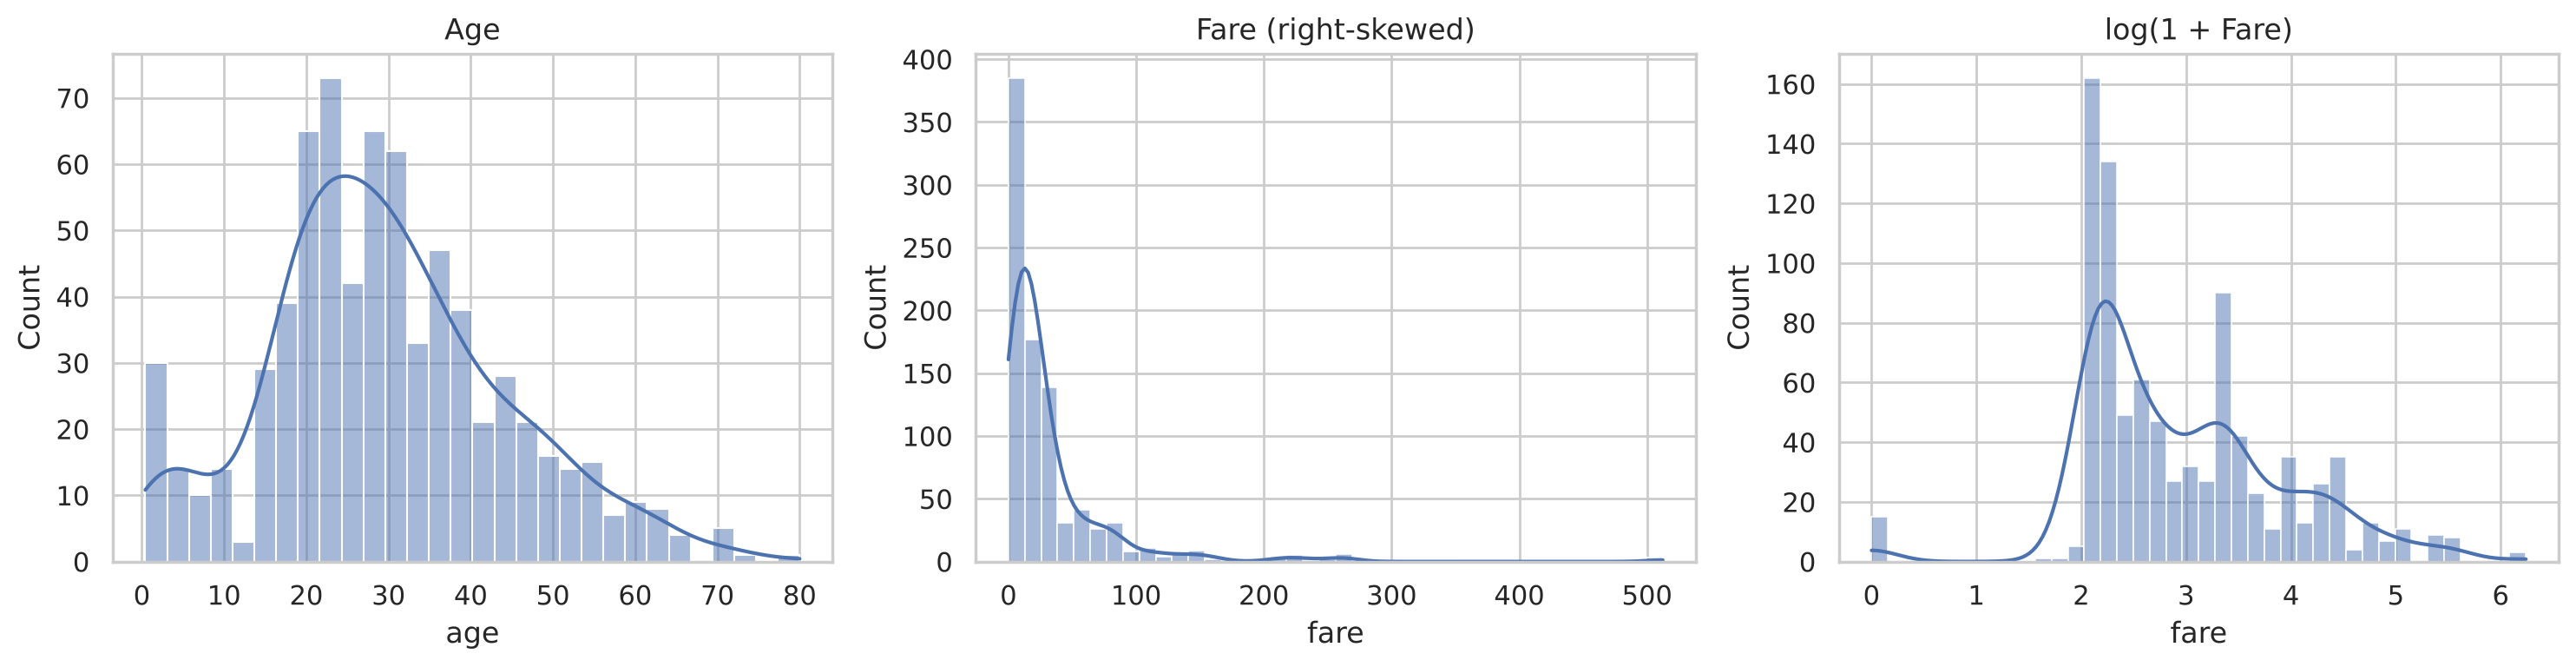

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(df["age"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age")
sns.histplot(df["fare"], bins=40, kde=True, ax=axes[1])
axes[1].set_title("Fare (right-skewed)")
sns.histplot(np.log1p(df["fare"]), bins=40, kde=True, ax=axes[2])
axes[2].set_title("log(1 + Fare)")
plt.tight_layout()
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

توزیع `fare` به‌شدت **چوله به راست (right-skewed)** است: بیشتر بلیت‌ها ارزان‌اند و چند بلیت بسیار گران. برای مدل‌های خطی، اعمال تبدیل لگاریتمی معمولاً توزیع را متقارن‌تر و مدل را پایدارتر می‌کند.

## ۴. تحلیل دومتغیره: کدام ویژگی‌ها با هدف رابطه دارند؟

</div>

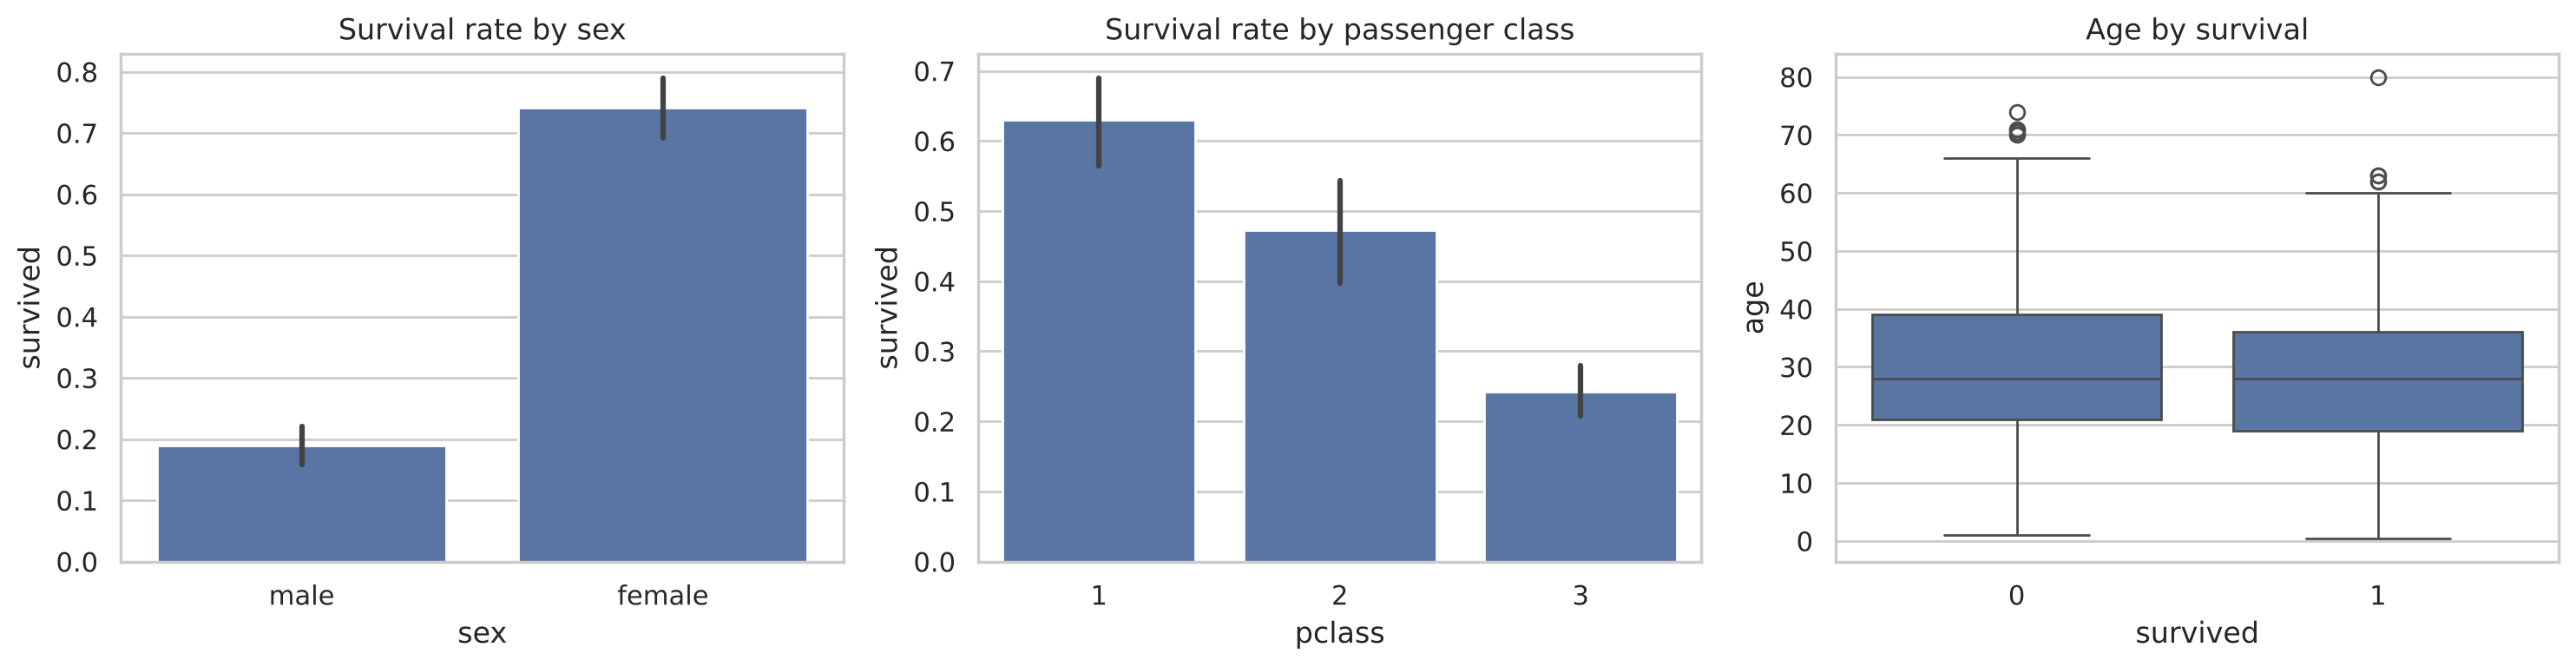

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(data=df, x="sex", y="survived", ax=axes[0])
axes[0].set_title("Survival rate by sex")
sns.barplot(data=df, x="pclass", y="survived", ax=axes[1])
axes[1].set_title("Survival rate by passenger class")
sns.boxplot(data=df, x="survived", y="age", ax=axes[2])
axes[2].set_title("Age by survival")
plt.tight_layout()
plt.show()

In [8]:
df.groupby(["sex", "pclass"])["survived"].mean().unstack().round(2)

pclass,1,2,3
sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

یافته‌های مهم:
- نرخ نجات زنان (حدود ۷۴٪) بسیار بیشتر از مردان (حدود ۱۹٪) است؛ قانون «اول زنان و کودکان».
- مسافران درجهٔ یک شانس بسیار بیشتری داشته‌اند.
- ترکیب این دو، تفاوت را شدیدتر می‌کند: زنان درجهٔ یک بیش از ۹۰٪ و مردان درجهٔ سه حدود ۱۴٪.

پس `sex` و `pclass` احتمالاً قوی‌ترین ویژگی‌ها هستند.

</div>

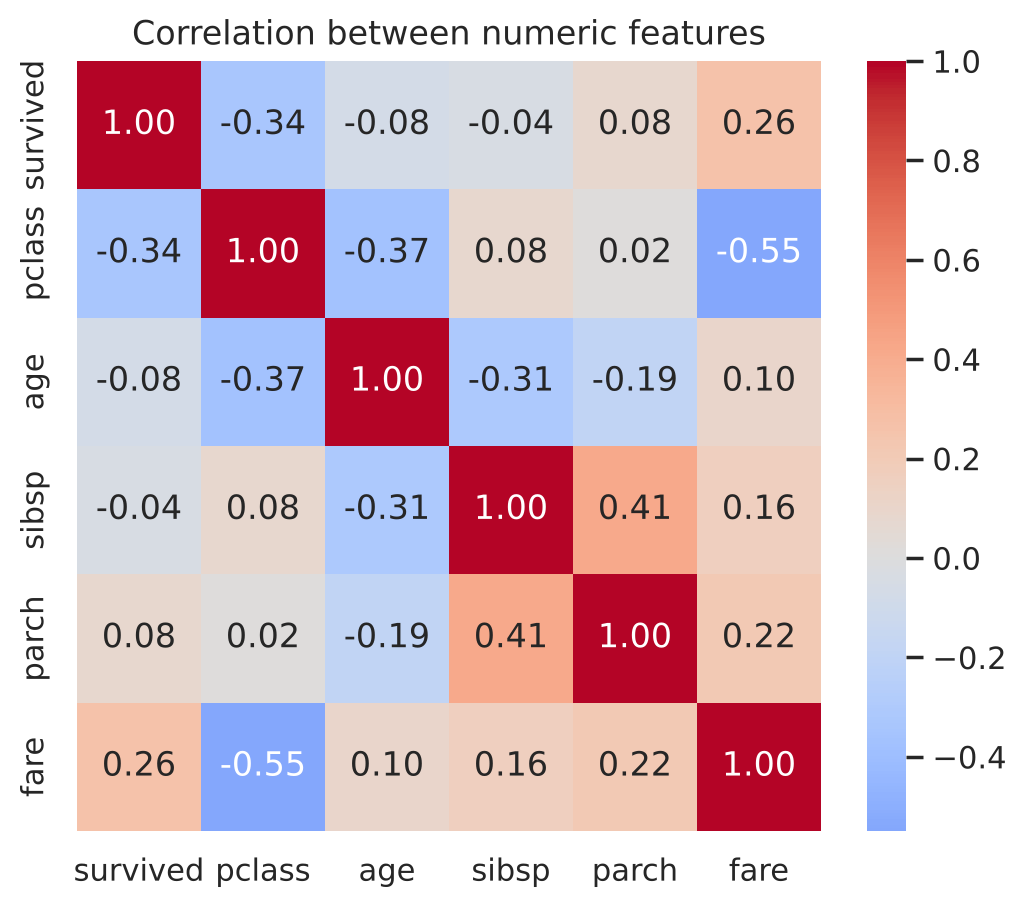

In [9]:
plt.figure(figsize=(6, 5))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation between numeric features")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

توجه: ضریب همبستگی پیرسون فقط رابطهٔ **خطی** را می‌سنجد. همبستگی کم به معنای بی‌ارتباطی نیست؛ مثلاً رابطهٔ سن با نجات غیرخطی است (کودکان شانس بیشتری داشتند).

## ۵. مهندسی ویژگی (Feature Engineering)

گاهی می‌توانیم از ترکیب ستون‌های موجود، ویژگی‌های معنادارتری بسازیم. اینجا تعداد اعضای خانوادهٔ همراه را از `sibsp` (خواهر، برادر و همسر) و `parch` (والدین و فرزندان) می‌سازیم:

</div>

In [10]:
df["family_size"] = df["sibsp"] + df["parch"] + 1
df.groupby("family_size")["survived"].agg(["mean", "count"]).round(2)

,mean,count
family_size,,
1,0.30,537
2,0.55,161
3,0.58,102
4,0.72,29
5,0.20,15
6,0.14,22
7,0.33,12
8,0.00,6
11,0.00,7


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

مسافران تنها و خانواده‌های خیلی بزرگ شانس کمتری داشته‌اند و خانواده‌های ۲ تا ۴ نفره بیشترین شانس را. این یک رابطهٔ غیرخطی است که در ستون‌های خام به این روشنی دیده نمی‌شد.

## ۶. رفع مقادیر گمشده

روش‌های رایج:

| روش | مناسب برای | نکته |
|---|---|---|
| حذف سطر | تعداد گمشدهٔ بسیار کم | داده از دست می‌رود |
| حذف ستون | درصد گمشدهٔ بسیار زیاد | مثل `deck` |
| پر کردن با میانگین | ویژگی عددی با توزیع متقارن | به دادهٔ پرت حساس است |
| پر کردن با میانه | ویژگی عددی چوله یا دارای دادهٔ پرت | انتخاب امن‌تر |
| پر کردن با پرتکرارترین مقدار | ویژگی دسته‌ای | مثل `embarked` |
| افزودن ستون نشانگر | وقتی «گمشده بودن» خودش اطلاعات دارد | `add_indicator=True` |

در scikit-learn از `SimpleImputer` استفاده می‌کنیم:

</div>

In [11]:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy="median")
ages = imputer.fit_transform(df[["age"]])
print("Median used for filling:", imputer.statistics_[0])
print("Missing after imputation:", np.isnan(ages).sum())

Median used for filling: 28.0
Missing after imputation: 0


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۷. تبدیل ویژگی‌های دسته‌ای به عدد

مدل‌ها فقط با عدد کار می‌کنند. دو نوع ویژگی دسته‌ای داریم:

- **اسمی (Nominal):** دسته‌ها ترتیب ندارند؛ مثل `sex` یا `embarked`. روش درست: **One-Hot Encoding**؛ برای هر دسته یک ستون صفر و یک می‌سازیم.
- **ترتیبی (Ordinal):** دسته‌ها ترتیب طبیعی دارند؛ مثل «کم، متوسط، زیاد». روش درست: **Ordinal Encoding** با ترتیب مشخص.

**اشتباه رایج:** اگر به `embarked` کدهای ۰، ۱ و ۲ بدهیم، مدل خطی فرض می‌کند بندر «۲» دو برابر بندر «۱» است که بی‌معناست. `LabelEncoder` فقط برای **برچسب هدف** طراحی شده، نه ویژگی‌ها.

</div>

In [12]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoded = ohe.fit_transform(df[["embarked"]].fillna("S"))
pd.DataFrame(encoded, columns=ohe.get_feature_names_out()).head()

,embarked_C,embarked_Q,embarked_S
0,0.0,0.0,1.0
1,1.0,0.0,0.0
2,0.0,0.0,1.0
3,0.0,0.0,1.0
4,0.0,0.0,1.0


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

پارامتر `handle_unknown="ignore"` باعث می‌شود اگر در دادهٔ آزمون دسته‌ای ببینیم که در آموزش نبوده، خطا رخ ندهد و همهٔ ستون‌های آن صفر شوند.

</div>

In [13]:
from sklearn.preprocessing import OrdinalEncoder

sizes = pd.DataFrame({"size": ["small", "large", "medium", "small"]})
ordinal = OrdinalEncoder(categories=[["small", "medium", "large"]])
sizes["size_encoded"] = ordinal.fit_transform(sizes[["size"]])
sizes

,size,size_encoded
0,small,0.0
1,large,2.0
2,medium,1.0
3,small,0.0


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۸. مقیاس‌بندی ویژگی‌ها (Feature Scaling)

ویژگی‌ها مقیاس‌های بسیار متفاوتی دارند: `age` بین ۰ تا ۸۰ و `fare` بین ۰ تا ۵۰۰. برای مدل‌هایی که با **فاصله** (مثل k-NN، SVM و K-Means) یا **گرادیان** (مثل رگرسیون لجستیک و شبکهٔ عصبی) کار می‌کنند، ویژگی بزرگ‌تر بی‌دلیل اهمیت بیشتری پیدا می‌کند. مدل‌های درختی به مقیاس حساس نیستند.

- **استانداردسازی (StandardScaler):** میانگین صفر و انحراف معیار یک

$$z = \frac{x - \mu}{\sigma}$$

- **نرمال‌سازی کمینه-بیشینه (MinMaxScaler):** نگاشت به بازهٔ صفر تا یک

$$x' = \frac{x - x_{\min}}{x_{\max} - x_{\min}}$$

</div>

In [14]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

sample = df[["age", "fare"]].dropna()
scaled = pd.DataFrame({
    "age (raw)": sample["age"],
    "fare (raw)": sample["fare"],
    "age (standard)": StandardScaler().fit_transform(sample[["age"]]).ravel(),
    "fare (standard)": StandardScaler().fit_transform(sample[["fare"]]).ravel(),
    "fare (min-max)": MinMaxScaler().fit_transform(sample[["fare"]]).ravel(),
})
scaled.describe().loc[["mean", "std", "min", "max"]].round(2)

,age (raw),fare (raw),age (standard),fare (standard),fare (min-max)
mean,29.70,34.69,0.00,-0.00,0.07
std,14.53,52.92,1.00,1.00,0.10
min,0.42,0.00,-2.02,-0.66,0.00
max,80.00,512.33,3.47,9.03,1.00


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۹. نشت داده (Data Leakage): مهم‌ترین نکتهٔ این جلسه

**قانون طلایی:** هر چیزی که از داده **یاد گرفته می‌شود** (میانگین برای پر کردن، میانگین و انحراف معیار برای مقیاس‌بندی، دسته‌ها برای One-Hot، ویژگی‌های انتخاب‌شده و...) باید **فقط از دادهٔ آموزش** یاد گرفته شود. سپس همان تبدیل روی دادهٔ آزمون **اعمال** می‌شود.

اگر مثلاً `StandardScaler` را قبل از تقسیم داده روی کل داده `fit` کنیم، اطلاعاتی از دادهٔ آزمون به مدل نشت می‌کند و ارزیابی ما بیش از حد خوش‌بینانه می‌شود.

بیایید ببینیم این اشتباه چقدر می‌تواند گمراه‌کننده باشد. یک دادهٔ **کاملاً تصادفی** می‌سازیم: ۱۰۰ نمونه، ۱۰٬۰۰۰ ویژگی تصادفی و برچسب تصادفی. هیچ مدلی نباید بتواند بهتر از ۵۰٪ (شانس) عمل کند.

</div>

In [15]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline

rng = np.random.default_rng(0)
X_noise = rng.normal(size=(100, 10_000))
y_noise = rng.integers(0, 2, size=100)

# WRONG: select the "best" features using all data, then evaluate
X_selected = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
wrong = cross_val_score(LogisticRegression(), X_selected, y_noise, cv=5).mean()

# RIGHT: feature selection is part of the model and is re-fitted inside each fold
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression())
right = cross_val_score(pipe, X_noise, y_noise, cv=5).mean()

print(f"With leakage:    {wrong:.2f}")
print(f"Without leakage: {right:.2f}")

With leakage:    0.87
Without leakage: 0.48


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با نشت داده، مدل روی **نویز خالص** دقتی بسیار بالاتر از شانس نشان می‌دهد؛ یک توهم کامل. بدون نشت، دقت به حدود ۵۰٪ برمی‌گردد که جواب درست است. (اعتبارسنجی متقابل یا `cross_val_score` را در جلسهٔ ۱۰ کامل یاد می‌گیریم؛ فعلاً بدانید که چند بار تقسیم آموزش/آزمون انجام می‌دهد و میانگین می‌گیرد.)

راه حل همیشگی: **Pipeline**.

## ۱۰. Pipeline و ColumnTransformer: پیش‌پردازش به روش حرفه‌ای

- **`ColumnTransformer`** به هر گروه از ستون‌ها تبدیل مخصوص خودش را اعمال می‌کند.
- **`Pipeline`** مراحل پیش‌پردازش و مدل را به یک شیء واحد تبدیل می‌کند. وقتی `fit` را صدا می‌زنیم، همهٔ مراحل فقط روی دادهٔ آموزش یاد می‌گیرند و هنگام `predict`، همان تبدیل‌ها روی دادهٔ جدید اعمال می‌شوند. **نشت داده عملاً غیرممکن می‌شود.**

ابتدا داده را تقسیم می‌کنیم. تبدیل‌هایی که چیزی یاد نمی‌گیرند (مثل ساختن `family_size`) را می‌توان قبل از تقسیم انجام داد.

</div>

In [16]:
from sklearn.model_selection import train_test_split

features = ["pclass", "sex", "age", "sibsp", "parch", "fare", "embarked", "family_size"]
X = df[features]
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (712, 8)  Test: (179, 8)


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

numeric_features = ["age", "sibsp", "parch", "family_size", "pclass"]
skewed_features = ["fare"]
categorical_features = ["sex", "embarked"]

numeric_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

skewed_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one")),
    ("scale", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("skewed", skewed_pipeline, skewed_features),
    ("cat", categorical_pipeline, categorical_features),
])

model = Pipeline([
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000)),
])
model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('skewed', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

نمایش بالا ساختار کامل مدل را نشان می‌دهد (در Jupyter و Colab به‌صورت تعاملی). حالا کل Pipeline را با یک دستور آموزش می‌دهیم و ارزیابی می‌کنیم:

</div>

In [18]:
from sklearn.dummy import DummyClassifier

model.fit(X_train, y_train)
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)

print(f"Baseline accuracy:            {baseline.score(X_test, y_test):.3f}")
print(f"Logistic regression accuracy: {model.score(X_test, y_test):.3f}")

Baseline accuracy:            0.615
Logistic regression accuracy: 0.810


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

مدل ما با یک پیش‌پردازش درست، به‌وضوح از مدل پایه بهتر است. ویژگی‌های نهایی که مدل دیده را هم می‌توانیم ببینیم:

</div>

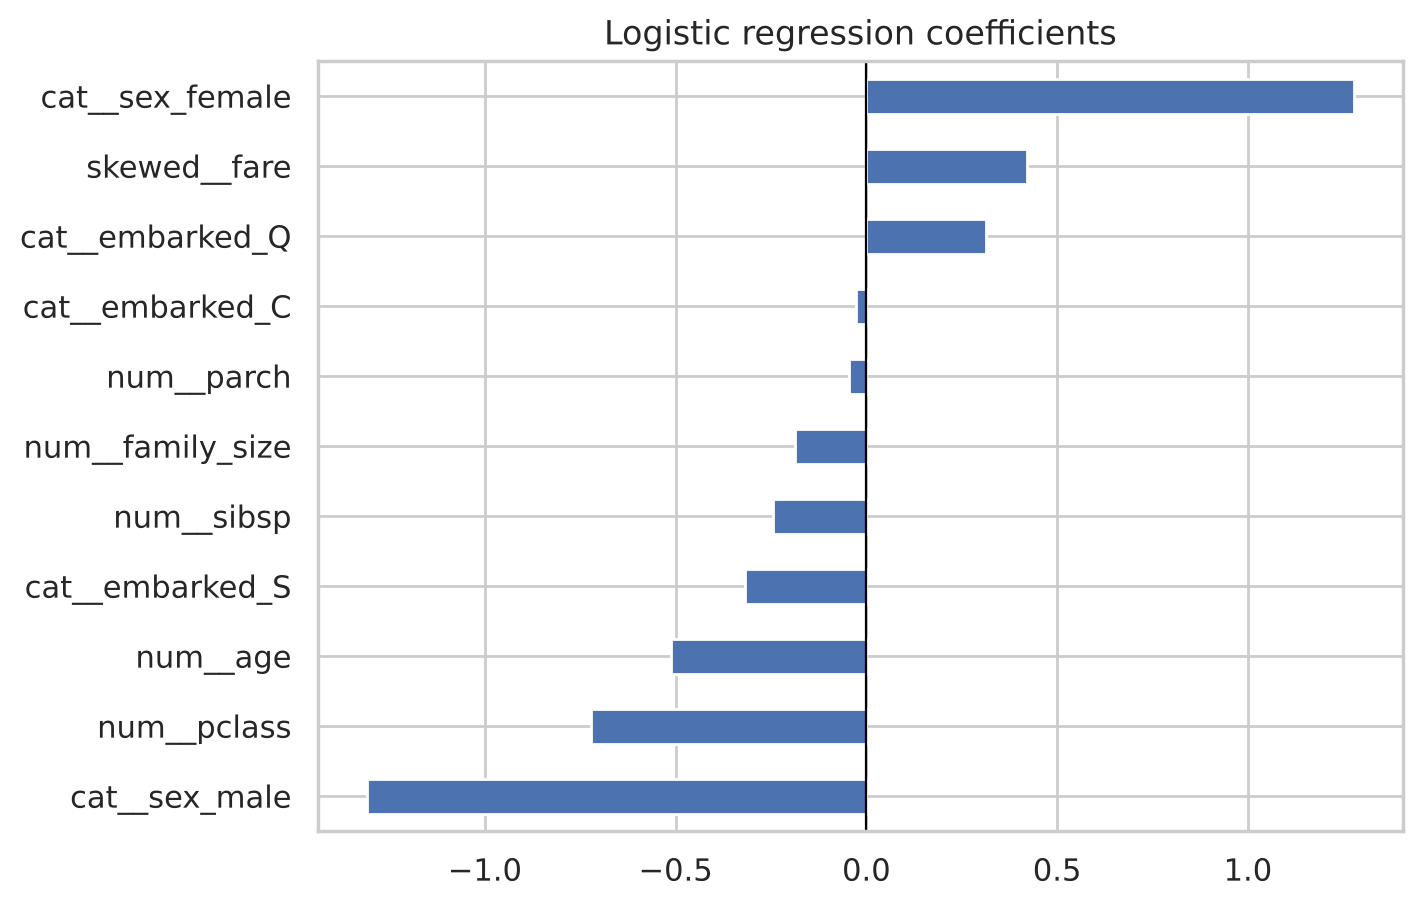

In [19]:
feature_names = model.named_steps["preprocess"].get_feature_names_out()
coefficients = model.named_steps["classifier"].coef_[0]
pd.Series(coefficients, index=feature_names).sort_values().plot.barh(figsize=(7, 5))
plt.title("Logistic regression coefficients")
plt.axvline(0, color="black", linewidth=0.8)
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

ضرایب مثبت شانس نجات را بالا می‌برند و ضرایب منفی پایین. همان‌طور که در EDA دیدیم، زن بودن قوی‌ترین عامل مثبت و درجهٔ پایین‌تر (عدد بزرگ‌تر `pclass`) عامل منفی است. چون ویژگی‌ها استاندارد شده‌اند، اندازهٔ ضرایب عددی تقریباً قابل مقایسه است.

یک مزیت بزرگ دیگر Pipeline: مدل نهایی، دادهٔ **خام** می‌گیرد. برای پیش‌بینی یک مسافر جدید لازم نیست پیش‌پردازش را دستی تکرار کنیم:

</div>

In [20]:
passenger = pd.DataFrame([{
    "pclass": 3, "sex": "male", "age": np.nan, "sibsp": 0, "parch": 0,
    "fare": 8.05, "embarked": "S", "family_size": 1,
}])
print(f"Survival probability: {model.predict_proba(passenger)[0, 1]:.2f}")

Survival probability: 0.09


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## جمع‌بندی

- EDA را همیشه قبل از مدل‌سازی انجام دهید: ابعاد، نوع ستون‌ها، مقادیر گمشده، توزیع‌ها و رابطه با هدف.
- ستون‌هایی را که در لحظهٔ پیش‌بینی در دسترس نیستند حذف کنید (**نشت هدف**).
- برای ویژگی‌های اسمی از One-Hot و برای ترتیبی از Ordinal استفاده کنید؛ نه `LabelEncoder`.
- مقیاس‌بندی برای مدل‌های فاصله‌محور و گرادیان‌محور ضروری است، نه برای درخت‌ها.
- هر تبدیلی که از داده یاد می‌گیرد فقط باید روی دادهٔ آموزش `fit` شود. **Pipeline** این را تضمین می‌کند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. در `numeric_pipeline` به‌جای میانه از میانگین استفاده کنید و `add_indicator=True` را به `SimpleImputer` اضافه کنید. دقت تغییر می‌کند؟

۲. ویژگی جدید `is_alone` (یک اگر `family_size` برابر ۱ باشد) بسازید و به مدل اضافه کنید.

۳. ستون `alive` را عمداً به ویژگی‌ها اضافه کنید و دقت را ببینید. چرا این عدد بی‌ارزش است؟

۴. `LogisticRegression` را با `KNeighborsClassifier` عوض کنید. سپس `StandardScaler` را از Pipeline حذف کنید. چه اتفاقی برای دقت k-NN می‌افتد و چرا؟

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** در `numeric_pipeline` به‌جای میانه از میانگین استفاده کنید و `add_indicator=True` را به `SimpleImputer` اضافه کنید. دقت تغییر می‌کند؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** ویژگی جدید `is_alone` (یک اگر `family_size` برابر ۱ باشد) بسازید و به مدل اضافه کنید.

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** ستون `alive` را عمداً به ویژگی‌ها اضافه کنید و دقت را ببینید. چرا این عدد بی‌ارزش است؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** `LogisticRegression` را با `KNeighborsClassifier` عوض کنید. سپس `StandardScaler` را از Pipeline حذف کنید. چه اتفاقی برای دقت k-NN می‌افتد و چرا؟

</div>

In [ ]:
# پاسخ خود را اینجا بنویسید
